# Previsão do desempenho final de estudantes

## Contexto e pergunta
A base usada foi a Student Performance, que traz informções de estudantes de escolas portuguesas, disponível no [Kaggle}](https://www.kaggle.com/datasets/whenamancodes/student-performance)
A pergunta respondida é se é possível estimar a nota final `G3` de matemática usando idade, tempo semanal de estudo, reprovações anteriores, faltas e as notas dos dois períodos anteriores?

O alvo é `G3`, nota final de matemática na escala de 0 a 20. As entradas são `age`, `studytime`, `failures`, `absences` e `G1`/`G2`. As categorias textuais não entram neste modelo (poderiam entrar na analise com o get_dummies); os atributos selecionados são numéricos.

In [12]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

In [14]:
dfM = pd.read_csv("Maths.csv")

print(f"Dimensões da base: {dfM.shape[0]} linhas x {dfM.shape[1]} colunas")
print("Tipos das colunas:")
display(dfM.dtypes)
print("Primeiras cinco linhas:")
display(dfM.head())

Dimensões da base: 397 linhas x 33 colunas
Tipos das colunas:


school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object

Primeiras cinco linhas:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [15]:
linhas_iniciais = len(dfM)
duplicatas = dfM.duplicated().sum()
ausentes_por_coluna = dfM.isna().sum()

print(f"Registros iniciais: {linhas_iniciais}")
print(f"Duplicatas encontradas: {duplicatas}")
print("Valores ausentes por coluna:")
display(ausentes_por_coluna[ausentes_por_coluna > 0])

# Remoção justificada: duplicatas repetem observações e linhas incompletas não serão usadas no modelo.
dfM = dfM.drop_duplicates().dropna()
print(f"Registros após limpeza: {len(dfM)}")

Registros iniciais: 397
Duplicatas encontradas: 2
Valores ausentes por coluna:


Series([], dtype: int64)

Registros após limpeza: 395


In [16]:
features = [
    "age",
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

X = dfM[features]
y = dfM["G3"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [17]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R²: {r2:.3f}")
print(f"MAE: {mae:.3f} pontos")
print(f"MSE: {mse:.3f}")
print(f"RMSE: {rmse:.3f} pontos")

R²: 0.782
MAE: 1.334 pontos
MSE: 4.462
RMSE: 2.112 pontos


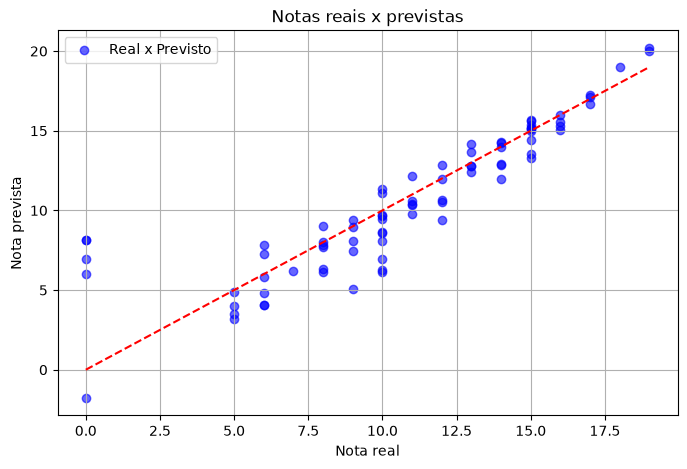

In [18]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color='blue', alpha=0.6, label='Real x Previsto')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title('Notas reais x previstas')
plt.xlabel('Nota real')
plt.ylabel('Nota prevista')
plt.legend()
plt.grid(True)
plt.show()

## Discussão crítica e conclusões

### 1. Interpretação das métricas
R^2 Deu 0,782; MAE de 1,33 e RMSE de 2,11 - o que indica que o modelo "entende" a variação dos dados de treino, apresentando baixo erro méido. O RMSE ser maior que o MAE mostra que houve erros grandes que levaram à maior pnealidade. O resultado é interessante para estimativas mas não deve ser usado para recomendar decisões reais, já que o modelo foi treinado para esse contexto específico, além do fato de que uma máquina não pode admitir responsabilidade por um decisão de gerenciamento, etc

### 2. Diagnóstico dos erros
No gráfico de valores reais e previstos, muitos pontos ficam próximos da linha de referência. São presentes, porém, casos com nota real 0 e previsão entre cerca de 6,95 e 8,16, nos quais o modelo superestima bastante. Portanto, o desempenho médio esconde erros muito relevantes para alguns estudantes. Esses casos devem ser investigados e não tratados como previsões confiáveis.

### 3. Limitações e próximos passos
A base representa apenas duas escolas e a divisão aleatória não mede diretamente a transferência para outras escolas ou anos. A regressão linear também não captura relações não lineares ou grupos com padrões diferentes (como visto nos valores 0 do gráfico). Outros dados potencialmente úteis incluem contexto socioeconômico, apoio pedagógico, histórico escolar mais amplo, turma/professor e informações de saúde ou motivação, que não foram incluídos tanto para simplificar o simulador quanto para treinar um modelo possivelmente mais genérico. Algumas variáveis familiares e escolares já existem na base completa, mas não foram selecionadas neste modelo. `G1` e `G2` são preditores fortes, porém só podem ser usados quando forem conhecidas.

In [19]:
def ler_inteiro(prompt, exemplo):
    resposta = input(f"{prompt} [exemplo: {exemplo}] > ").strip()
    return int(resposta) if resposta else exemplo


idade = ler_inteiro("Digite sua idade", 16)
tempo_estudo = ler_inteiro("Tempo semanal de estudo (1: <2h, 2: 2-5h, 3: 5-10h, 4: >10h)", 2)
tranca = ler_inteiro("Número de reprovações anteriores (0 a 3)", 0)
faltas = ler_inteiro("Número de faltas", 4)
G1 = ler_inteiro("Nota do primeiro período (0 a 20)", 12)
G2 = ler_inteiro("Nota do segundo período (0 a 20)", 13)

dados = {
    "age": idade,
    "studytime": tempo_estudo,
    "failures": tranca,
    "absences": faltas,
    "G1": G1,
    "G2": G2,
}

entrada = pd.DataFrame([dados], columns=features)
estimado = np.clip(modelo.predict(entrada)[0], 0, 20)
print(f"Nota final estimada: {estimado:.1f}/20")

Nota final estimada: 12.9/20


In [ ]:
# usando valoresde texto
X_completo = pd.get_dummies(
    dfM.drop(columns=["G3"]),
    drop_first=True,
    dtype=int
)
y_completo = dfM["G3"]

X_treino_dummy, X_teste_dummy, y_treino_dummy, y_teste_dummy = train_test_split(
    X_completo,
    y_completo,
    test_size=0.2,
    random_state=42
)

modelo_dummy = LinearRegression()
modelo_dummy.fit(X_treino_dummy, y_treino_dummy)

y_previsto_dummy = modelo_dummy.predict(X_teste_dummy)

print(f"R²: {r2_score(y_teste_dummy, y_previsto_dummy):.3f}")
print(f"MAE: {mean_absolute_error(y_teste_dummy, y_previsto_dummy):.3f} pontos")
print(f"RMSE: {np.sqrt(mean_squared_error(y_teste_dummy, y_previsto_dummy)):.3f} pontos")

R²: 0.724
MAE: 1.647 pontos
RMSE: 2.378 pontos
